# NDT Analysis

Determines the best way to estimate per-subject non-decision time (NDT) for
`pigeon.data.get_bounds`, and documents the analysis behind that decision.

## Background

NDT is the delay between the decision (the pigeon crossing the bound) and the
key press. We estimate it per subject via congruence: for each candidate lag
`k` (steps back from the response), check whether `sign(midpoint position at
lag k)` matches the eventual choice; the lag that maximizes this congruence
is the estimated NDT.

## Part 1 — Does the peak lag depend on SNR?

For each subject, the congruence-vs-lag profile is computed separately for
each block (1-6) of the OL task. Blocks 1-3 use one SNR level; blocks 4-6 use
a different (higher) SNR level. If NDT is a stable sensorimotor property, the
peak congruence lag should be the same across blocks and SNR conditions
within a subject.

**Block pairs compared:** 1 vs 4, 2 vs 5, 3 vs 6.

## Part 2 — Why, and what to do about it

Part 1 finds that peak lag does shift with SNR. Physiologically, NDT itself
should *not* depend on SNR -- it's motor delay, not part of the decision
process. Part 2 shows this is a measurement artifact (lower SNR produces more
backward pigeon movement after the true crossing, which is what lets the
congruence method sharply localize the crossing lag; at high SNR there's too
little backward movement to identify it, so the curve stays flat across
several lags), checks how reliable a low-SNR-only estimate actually is, and
concludes with the approach now implemented in `get_bounds` by default: NDT
estimated from each subject's lowest-|SNR| trials only, search restricted to
lags 1-3 (NDT=0 and NDT>=4 aren't physiologically plausible), applied
uniformly to all of that subject's trials regardless of SNR.

In [1]:
import sys, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

sys.path.insert(0, os.path.dirname(os.getcwd()))
from pigeon.data import get_data_table, get_bounds

MAX_NDT = 5
LAGS    = np.arange(MAX_NDT)

In [2]:
# Load OL data keeping original block numbering (1–6)
data = get_data_table(task_type='OL', combine_snr=False, correct_bias=None)

subjects = sorted(data['subject_index'].dropna().unique())
blocks   = sorted(data['block_index'].dropna().unique().astype(int))

print(f'{len(subjects)} subjects')
print(f'Blocks present: {blocks}')
print(f'Trials total:   {len(data):,}')

# Show SNR per block (should be one value per block in blocked design)
for b in blocks:
    snrs = data.loc[data['block_index'] == b, 'snr'].dropna().unique()
    print(f'  Block {b}: SNR = {np.round(snrs, 3)}')

  1: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-21_14h39.24.096.csv
  2: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-21_15h37.48.260.csv
  3: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-21_16h34.46.761.csv
  4: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-21_16h35.25.285.csv
  5: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-21_16h36.33.669.csv
  6: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-21_16h36.41.364.csv
  7: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-21_16

 14: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-21_17h35.53.048.csv
 15: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-21_17h48.56.013.csv
 16: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-21_19h38.38.956.csv
 17: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-21_22h36.04.663.csv
 18: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-21_22h36.05.544.csv
 19: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-21_22h36.07.852.csv
 20: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-21_22

 28: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-21_22h40.06.581.csv
 29: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-21_22h41.15.620.csv
 30: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-21_22h42.16.563.csv
 31: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-21_22h46.46.975.csv
 32: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-21_22h54.23.759.csv
 33: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-21_23h30.52.958.csv
 34: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-21_23

 42: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-21_23h38.40.851.csv
 43: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-21_23h39.13.059.csv
 44: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-21_23h41.40.441.csv
 45: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-21_23h42.52.039.csv
 46: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-21_23h42.54.723.csv
 47: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-21_23h49.12.728.csv
 48: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-22_01

 55: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-22_24h37.37.464.csv
 56: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-22_24h38.28.207.csv
 57: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-22_24h39.12.114.csv
 58: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-22_24h40.02.817.csv
 59: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-22_24h40.07.382.csv
 60: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-22_24h41.01.524.csv


60 subjects
Blocks present: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]
Trials total:   42,252
  Block 1: SNR = [ 0.333 -0.333]
  Block 2: SNR = [ 0.333 -0.333]
  Block 3: SNR = [-0.333  0.333]
  Block 4: SNR = [-1.  1.]
  Block 5: SNR = [-1.  1.]
  Block 6: SNR = [-1.  1.]


In [3]:
# Compute per-block congruence profiles for each subject.
# cong_data[subj][block] = dict with 'cong' (MAX_NDT,) and 'snr' (float)

MIN_TRIALS = 15   # skip block if too few trials

cong_data = {subj: {} for subj in subjects}

for subj in subjects:
    subj_data = data[data['subject_index'] == subj]
    for block in blocks:
        bd = subj_data[subj_data['block_index'] == block]
        # keep trials with valid steps, choices, and RT > 2. Also apply the two
        # standard-filter criteria that don't depend on NDT: trial_number >= 10
        # (skip warm-up trials) and wall_hit exclusion. DT itself is
        # intentionally NOT used as a filter here — this notebook estimates
        # NDT, and DT = RT - NDT - 1, so filtering on DT would be circular
        # (it would require already knowing the NDT this notebook is trying
        # to estimate).
        bd = bd[bd['steps'].apply(lambda s: s is not None and len(s) > 0)]
        bd = bd[np.isfinite(bd['choice'])]
        bd = bd[bd['RT'] > 2]
        bd = bd[bd['trial_number'] >= 10]
        bd = bd[bd['wall_hit'] == False]
        if len(bd) < MIN_TRIALS:
            continue

        steps_list = list(bd['steps'])
        choices    = bd['choice'].values.astype(float)
        # abs(snr): the raw `snr` column is signed (positive/negative drift).
        # Use |SNR| so blocks with roughly balanced left/right trials (e.g.
        # blocks 4-6, |SNR|~1.0) don't show a median near 0 just because
        # positive and negative signed values cancel out.
        snr_val    = float(np.nanmedian(np.abs(bd['snr'])))

        try:
            _, _, _, cong, _ = get_bounds(
                steps_list, choices,
                max_ndt=MAX_NDT,
                rt_cutoff_threshold=None,   # no RT filter — want full profile
            )
            # cong shape: (MAX_NDT, n_snrs); single block → n_snrs=1
            cong_data[subj][block] = {
                'cong': cong[:, 0],
                'snr':  snr_val,
                'n':    len(bd),
            }
        except Exception as exc:
            print(f'  S{subj} B{block}: {exc}')

n_complete = sum(
    1 for s in subjects
    if all(b in cong_data[s] for b in [1,2,3,4,5,6])
)
print(f'Done. {n_complete}/{len(subjects)} subjects have all 6 blocks.')

Done. 44/60 subjects have all 6 blocks.


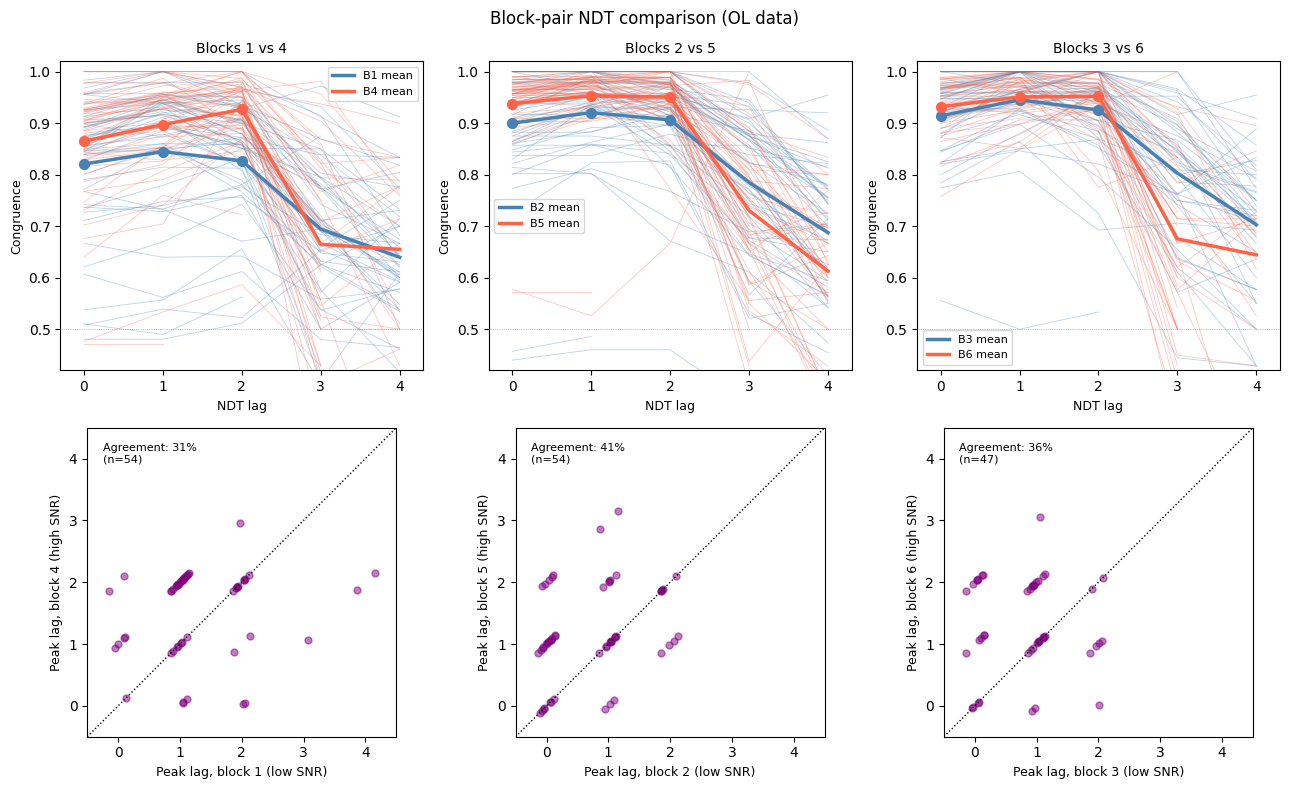

In [4]:
# ── Block-pair comparison plots ───────────────────────────────────────────────
# For each pair (1v4, 2v5, 3v6): overlay congruence profiles from both blocks
# per subject, and show scatter of peak lags.
# Filled dots on mean curves = points where normalized congruence > 0.9.

BLOCK_PAIRS = [(1, 4), (2, 5), (3, 6)]

fig, axs = plt.subplots(2, 3, figsize=(13, 8))

# Top row: overlay congruence profiles for all subjects per block pair
for pi, (b_lo, b_hi) in enumerate(BLOCK_PAIRS):
    ax = axs[0, pi]
    for subj in subjects:
        if b_lo not in cong_data[subj] or b_hi not in cong_data[subj]:
            continue
        clo = cong_data[subj][b_lo]['cong']
        chi = cong_data[subj][b_hi]['cong']
        ax.plot(LAGS, clo, color='steelblue', lw=0.6, alpha=0.35)
        ax.plot(LAGS, chi, color='tomato',    lw=0.6, alpha=0.35)

    # Mean across subjects
    clo_all = np.array([cong_data[s][b_lo]['cong'] for s in subjects if b_lo in cong_data[s]])
    chi_all = np.array([cong_data[s][b_hi]['cong'] for s in subjects if b_hi in cong_data[s]])
    if len(clo_all):
        mean_lo = np.nanmean(clo_all, axis=0)
        ax.plot(LAGS, mean_lo, color='steelblue', lw=2.5, label=f'B{b_lo} mean')
        lo_max = np.nanmax(mean_lo)
        if lo_max > 0:
            high_mask = (mean_lo / lo_max) > 0.9
            if np.any(high_mask):
                ax.scatter(LAGS[high_mask], mean_lo[high_mask],
                           color='steelblue', s=50, zorder=6)
    if len(chi_all):
        mean_hi = np.nanmean(chi_all, axis=0)
        ax.plot(LAGS, mean_hi, color='tomato', lw=2.5, label=f'B{b_hi} mean')
        hi_max = np.nanmax(mean_hi)
        if hi_max > 0:
            high_mask = (mean_hi / hi_max) > 0.9
            if np.any(high_mask):
                ax.scatter(LAGS[high_mask], mean_hi[high_mask],
                           color='tomato', s=50, zorder=6)

    ax.axhline(0.5, color='gray', lw=0.5, ls=':')
    ax.set_xlim(-0.3, MAX_NDT - 0.7)
    ax.set_ylim(0.42, 1.02)
    ax.set_xticks(LAGS)
    ax.set_title(f'Blocks {b_lo} vs {b_hi}', fontsize=10)
    ax.set_xlabel('NDT lag', fontsize=9)
    ax.set_ylabel('Congruence', fontsize=9)
    ax.legend(fontsize=8)

# Bottom row: scatter of peak lag (low-SNR block) vs peak lag (high-SNR block)
for pi, (b_lo, b_hi) in enumerate(BLOCK_PAIRS):
    ax = axs[1, pi]
    peak_lo, peak_hi = [], []
    for subj in subjects:
        if b_lo not in cong_data[subj] or b_hi not in cong_data[subj]:
            continue
        clo = cong_data[subj][b_lo]['cong']
        chi = cong_data[subj][b_hi]['cong']
        if np.all(np.isnan(clo)) or np.all(np.isnan(chi)):
            continue
        peak_lo.append(int(np.nanargmax(clo)))
        peak_hi.append(int(np.nanargmax(chi)))

    if peak_lo:
        # Same jitter offset for x and y so paired points stay coherent diagonally
        jitter = np.random.default_rng(0).uniform(-0.15, 0.15, len(peak_lo))
        jlo = np.array(peak_lo) + jitter
        jhi = np.array(peak_hi) + jitter
        ax.scatter(jlo, jhi, s=25, alpha=0.5, color='purple')

        agree = np.mean(np.array(peak_lo) == np.array(peak_hi))
        ax.text(0.05, 0.95, f'Agreement: {agree:.0%}\n(n={len(peak_lo)})',
                transform=ax.transAxes, fontsize=8, va='top')

    ax.plot([-0.5, MAX_NDT - 0.5], [-0.5, MAX_NDT - 0.5], 'k:', lw=1)
    ax.set_xlim(-0.5, MAX_NDT - 0.5)
    ax.set_ylim(-0.5, MAX_NDT - 0.5)
    ax.set_xticks(LAGS); ax.set_yticks(LAGS)
    ax.set_xlabel(f'Peak lag, block {b_lo} (low SNR)', fontsize=9)
    ax.set_ylabel(f'Peak lag, block {b_hi} (high SNR)', fontsize=9)
    ax.set_aspect('equal')

fig.suptitle('Block-pair NDT comparison (OL data)', fontsize=12)
plt.tight_layout()
plt.show()

In [5]:
# ── Summary: peak lag distribution and within-subject consistency ─────────────

print('Peak NDT lag distribution per block:')
print(f'{"Block":>7}  {"SNR":>6}  {"n":>5}  Peak lag counts (lag 0..4)')
print('-' * 55)
for block in blocks:
    peaks = []
    snrs  = []
    for subj in subjects:
        if block not in cong_data[subj]:
            continue
        cong = cong_data[subj][block]['cong']
        if np.all(np.isnan(cong)):
            continue
        peaks.append(int(np.nanargmax(cong)))
        snrs.append(cong_data[subj][block]['snr'])
    counts = np.bincount(peaks, minlength=MAX_NDT)
    snr_med = np.median(snrs) if snrs else np.nan
    print(f'{block:>7}  {snr_med:>6.2f}  {len(peaks):>5}  {counts}')

print()
print('Within-subject peak-lag consistency across all 6 blocks:')
all_same, majority_same = 0, 0
for subj in subjects:
    peaks = [int(np.nanargmax(cong_data[subj][b]['cong']))
             for b in blocks if b in cong_data[subj]
             and not np.all(np.isnan(cong_data[subj][b]['cong']))]
    if len(peaks) < 2:
        continue
    mode_count = max(np.bincount(peaks))
    if mode_count == len(peaks):
        all_same += 1
    if mode_count >= len(peaks) / 2:
        majority_same += 1

n_valid = sum(1 for s in subjects if sum(b in cong_data[s] for b in blocks) >= 2)
print(f'  All 6 blocks agree:       {all_same}/{n_valid} ({100*all_same/n_valid:.0f}%)')
print(f'  Majority (≥3/6) agree:    {majority_same}/{n_valid} ({100*majority_same/n_valid:.0f}%)')

Peak NDT lag distribution per block:
  Block     SNR      n  Peak lag counts (lag 0..4)
-------------------------------------------------------
      1    0.33     59  [ 7 31 18  1  2]
      2    0.33     56  [25 22  9  0  0]
      3    0.33     49  [16 24  9  0  0]
      4    1.00     55  [ 6 15 33  1  0]
      5    1.00     58  [11 28 17  2  0]
      6    1.00     52  [11 21 19  1  0]

Within-subject peak-lag consistency across all 6 blocks:
  All 6 blocks agree:       1/60 (2%)
  Majority (≥3/6) agree:    53/60 (88%)


---
## Part 2 — Why does peak lag depend on SNR, and what should we do about it?

Uses MX and OL (2-3 discrete SNR levels each, `combine_snr=True` -- the standard
production loading), not the OL-specific 6-block structure from Part 1.

  1: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_09h13.45.625.csv
  2: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_10h11.56.537.csv
  3: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_10h12.28.806.csv
  4: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_10h13.05.149.csv
  5: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_10h13.09.605.csv
  6: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_10h13.30.507.csv
  7: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_10

 15: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_16h12.16.148.csv
 16: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_16h12.31.520.csv
 17: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_16h12.41.484.csv
 18: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_16h14.52.557.csv
 19: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_16h18.44.254.csv
 20: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_16h19.33.518.csv
 21: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_16

 28: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_17h12.43.591.csv
 29: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_17h12.53.031.csv
 30: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_17h13.00.949.csv
 31: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_17h13.12.054.csv
 32: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_17h13.15.803.csv
 33: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_17h13.22.933.csv
 34: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_17

 40: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_17h21.56.825.csv
 41: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_17h23.15.258.csv
 42: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_17h23.37.400.csv
 43: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_17h29.44.495.csv
 44: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_18h13.06.340.csv
 45: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_18h13.07.354.csv
 46: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_18

 53: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_18h18.52.475.csv
 54: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_18h19.57.520.csv
 55: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_18h26.10.569.csv
 56: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_18h49.58.399.csv
 57: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_18h53.32.854.csv
 58: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_19h25.58.493.csv
 59: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-12-06_12

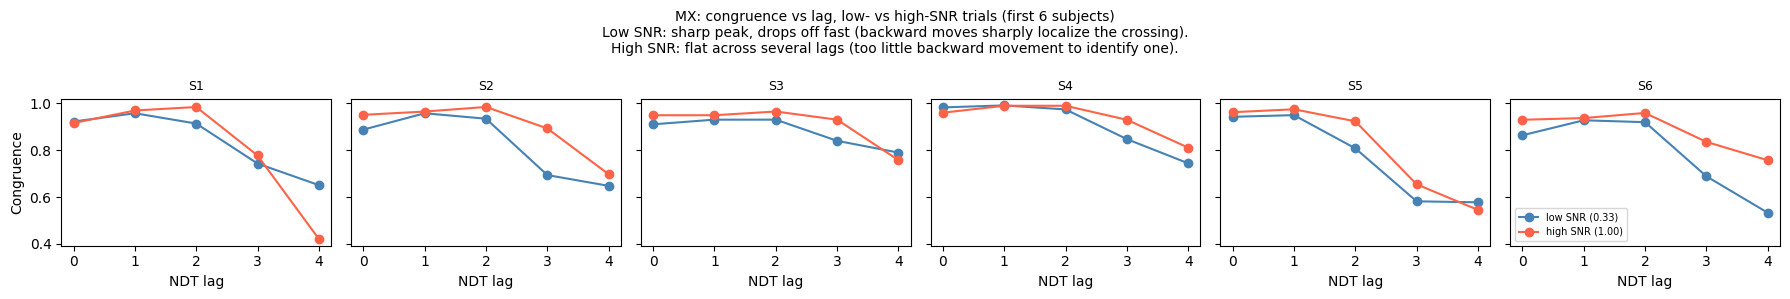

In [6]:
# ── Example congruence curves: low SNR (sharp) vs high SNR (flat) ─────────────
from pigeon.data import get_data_table, get_bounds

EXAMPLE_TASK = 'MX'
N_EXAMPLES   = 6

dt_ex = get_data_table(task_type=EXAMPLE_TASK, combine_snr=True, correct_bias=None)
subs_ex = sorted(dt_ex['subject_index'].unique())[:N_EXAMPLES]

fig, axs = plt.subplots(1, N_EXAMPLES, figsize=(3 * N_EXAMPLES, 3), sharey=True)
for ax, subj in zip(axs, subs_ex):
    sdt = dt_ex[dt_ex['subject_index'] == subj]
    snr = sdt['snr'].abs().to_numpy()
    uniq = np.unique(snr[np.isfinite(snr)])
    steps = sdt['steps'].tolist()
    choices = sdt['choice'].to_numpy()
    _, _, _, cong, _ = get_bounds(steps, choices, snr=snr, ndt=None, max_ndt=MAX_NDT)
    for ci, (snr_val, color, label) in enumerate(zip(uniq, ['steelblue', 'tomato'], ['low SNR', 'high SNR'])):
        if ci >= cong.shape[1]:
            continue
        ax.plot(LAGS, cong[:, ci], 'o-', color=color, label=f'{label} ({snr_val:.2f})')
    ax.set_title(f'S{int(subj)}', fontsize=9)
    ax.set_xlabel('NDT lag')
    ax.set_xticks(LAGS)
ax = axs[0]
ax.set_ylabel('Congruence')
axs[-1].legend(fontsize=7, loc='lower left')
fig.suptitle(f'{EXAMPLE_TASK}: congruence vs lag, low- vs high-SNR trials (first {N_EXAMPLES} subjects)\n'
             'Low SNR: sharp peak, drops off fast (backward moves sharply localize the crossing).\n'
             'High SNR: flat across several lags (too little backward movement to identify one).',
             fontsize=10)
plt.tight_layout()
plt.show()

  1: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_09h13.45.625.csv
  2: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_10h11.56.537.csv
  3: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_10h12.28.806.csv
  4: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_10h13.05.149.csv
  5: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_10h13.09.605.csv
  6: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_10h13.30.507.csv
  7: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_10

 15: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_16h12.16.148.csv
 16: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_16h12.31.520.csv
 17: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_16h12.41.484.csv
 18: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_16h14.52.557.csv
 19: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_16h18.44.254.csv
 20: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_16h19.33.518.csv
 21: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_16

 28: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_17h12.43.591.csv
 29: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_17h12.53.031.csv
 30: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_17h13.00.949.csv
 31: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_17h13.12.054.csv
 32: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_17h13.15.803.csv
 33: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_17h13.22.933.csv
 34: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_17

 40: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_17h21.56.825.csv
 41: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_17h23.15.258.csv
 42: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_17h23.37.400.csv
 43: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_17h29.44.495.csv
 44: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_18h13.06.340.csv
 45: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_18h13.07.354.csv
 46: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_18

 53: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_18h18.52.475.csv
 54: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_18h19.57.520.csv
 55: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_18h26.10.569.csv
 56: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_18h49.58.399.csv
 57: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_18h53.32.854.csv
 58: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_19h25.58.493.csv
 59: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-12-06_12

...

 14: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-21_17h35.53.048.csv
 15: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-21_17h48.56.013.csv
 16: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-21_19h38.38.956.csv
 17: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-21_22h36.04.663.csv
 18: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-21_22h36.05.544.csv
 19: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-21_22h36.07.852.csv
 20: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-21_22

 28: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-21_22h40.06.581.csv
 29: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-21_22h41.15.620.csv
 30: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-21_22h42.16.563.csv
 31: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-21_22h46.46.975.csv
 32: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-21_22h54.23.759.csv
 33: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-21_23h30.52.958.csv
 34: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-21_23

 41: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-21_23h38.40.806.csv
 42: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-21_23h38.40.851.csv
 43: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-21_23h39.13.059.csv
 44: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-21_23h41.40.441.csv
 45: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-21_23h42.52.039.csv
 46: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-21_23h42.54.723.csv
 47: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-21_23

 54: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-22_24h37.32.380.csv
 55: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-22_24h37.37.464.csv
 56: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-22_24h38.28.207.csv
 57: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-22_24h39.12.114.csv
 58: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-22_24h40.02.817.csv
 59: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-22_24h40.07.382.csv
 60: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-22_24

OL: low-SNR peak lags {np.int64(0): np.int64(1), np.int64(1): np.int64(41), np.int64(2): np.int64(16), np.int64(4): np.int64(2)}, high-SNR peak lags {np.int64(0): np.int64(1), np.int64(1): np.int64(24), np.int64(2): np.int64(32), np.int64(3): np.int64(3)}


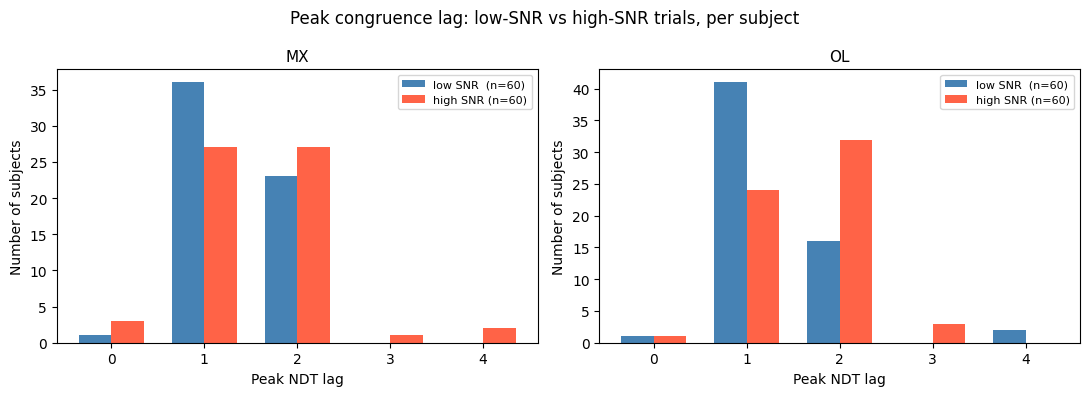

In [7]:
# ── Peak-lag distributions: low-SNR trials vs high-SNR trials, per subject ────
# (unrestricted argmax over all lags 0..MAX_NDT-1, to show the raw pattern
# before any [1,3] bounding is applied)

def per_snr_peak_lags(task_type):
    dt = get_data_table(task_type=task_type, combine_snr=True, correct_bias=None)
    subs = np.sort(dt['subject_index'].unique())
    low_peaks, high_peaks = [], []
    for subj in subs:
        sdt = dt[dt['subject_index'] == subj]
        snr = sdt['snr'].abs().to_numpy()
        uniq = np.unique(snr[np.isfinite(snr)])
        if len(uniq) < 2:
            continue
        steps = sdt['steps'].tolist()
        choices = sdt['choice'].to_numpy()
        _, _, _, cong, _ = get_bounds(steps, choices, snr=snr, ndt=None, max_ndt=MAX_NDT)
        col_low, col_high = cong[:, 0], cong[:, -1]
        if np.any(np.isfinite(col_low)):
            low_peaks.append(int(np.where(col_low == np.nanmax(col_low))[0][-1]))
        if np.any(np.isfinite(col_high)):
            high_peaks.append(int(np.where(col_high == np.nanmax(col_high))[0][-1]))
    return np.array(low_peaks), np.array(high_peaks)

fig, axs = plt.subplots(1, 2, figsize=(11, 4))
for ax, tt in zip(axs, ['MX', 'OL']):
    low, high = per_snr_peak_lags(tt)
    width = 0.35
    x = np.arange(MAX_NDT)
    low_counts  = np.bincount(low,  minlength=MAX_NDT)
    high_counts = np.bincount(high, minlength=MAX_NDT)
    ax.bar(x - width/2, low_counts,  width, color='steelblue', label=f'low SNR  (n={len(low)})')
    ax.bar(x + width/2, high_counts, width, color='tomato',    label=f'high SNR (n={len(high)})')
    ax.set_xticks(x)
    ax.set_xlabel('Peak NDT lag')
    ax.set_ylabel('Number of subjects')
    ax.set_title(tt, fontsize=11)
    ax.legend(fontsize=8)
    print(f'{tt}: low-SNR peak lags {dict(zip(x[low_counts>0], low_counts[low_counts>0]))}, '
          f'high-SNR peak lags {dict(zip(x[high_counts>0], high_counts[high_counts>0]))}')
fig.suptitle('Peak congruence lag: low-SNR vs high-SNR trials, per subject', fontsize=12)
plt.tight_layout()
plt.show()

**Consistent, reproducible pattern in both tasks**: low-SNR trials peak at lag 1
(sharp, fast drop-off after); high-SNR trials peak at lag 2 (flatter curve, several
lags nearly tied). This is not subject-to-subject noise -- it's the same shift in
the same direction in both independently-collected datasets.

**Why**: the congruence method identifies NDT by finding where the pigeon's
recent trajectory stops reliably predicting the final choice looking further back
in time. At low SNR, the accumulator drifts weakly, so it more often continues
moving (or reverses) after truly crossing the bound -- these backward/wandering
moves are exactly what let the method sharply localize the true crossing lag. At
high SNR, the accumulator moves decisively toward the bound and rarely reverses,
so congruence stays high across several lags and the method can't cleanly tell
them apart. This means pooling across SNR (or estimating a separate NDT per SNR
group) both let the flatter, less-identifying high-SNR curve pull the estimate
toward a lag that isn't really about NDT -- since NDT itself is a motor delay and
should not depend on SNR, the low-SNR estimate should be the more trustworthy one
for any given subject.

In [8]:
# ── Split-half reliability of the low-SNR-only estimate ───────────────────────
# If we only ever use a subject's own lowest-|SNR| trials, restricted to lags
# 1-3, how stable is that per-subject estimate given the amount of real data
# available? Split each subject's low-SNR trials randomly in half and check
# whether both halves land on the same peak lag.

rng_split = np.random.default_rng(0)

def split_half_agreement(task_type):
    dt = get_data_table(task_type=task_type, combine_snr=True, correct_bias=None)
    subs = np.sort(dt['subject_index'].unique())
    agree, total = 0, 0
    for subj in subs:
        sdt = dt[dt['subject_index'] == subj]
        snr = sdt['snr'].abs().to_numpy()
        uniq = np.unique(snr[np.isfinite(snr)])
        if len(uniq) < 2:
            continue
        low_snr = uniq.min()
        mask = np.isclose(snr, low_snr)
        idx = np.where(mask)[0]
        if len(idx) < 20:
            continue
        rng_split.shuffle(idx)
        half = len(idx) // 2
        steps = sdt['steps'].tolist()
        choices = sdt['choice'].to_numpy()
        ests = []
        for ii in [idx[:half], idx[half:]]:
            s = [steps[i] for i in ii]
            c = choices[ii]
            _, _, _, cong, _ = get_bounds(s, c, ndt=None, max_ndt=MAX_NDT)  # single group -> low-SNR-only, bounded [1,3]
            col = cong[:, 0]
            if np.any(np.isfinite(col)):
                ests.append(int(np.where(col == np.nanmax(col))[0][-1]))
        if len(ests) == 2:
            total += 1
            agree += int(ests[0] == ests[1])
    return agree, total

for tt in ['MX', 'OL']:
    agree, total = split_half_agreement(tt)
    print(f'{tt}: split-half agreement = {agree}/{total} ({100*agree/total:.0f}%)')

print()
print('Individually noisy (~60% agreement with only ~150-250 trials per subject),')
print('but this is the best-justified estimator given the mechanism above -- pooling')
print('or per-SNR-group estimation are not more reliable, just differently biased')
print('(see git history for the decisiveness comparison that also failed to favor')
print('either alternative for the subjects where they disagree with low-SNR-only).')

  1: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_09h13.45.625.csv
  2: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_10h11.56.537.csv
  3: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_10h12.28.806.csv
  4: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_10h13.05.149.csv
  5: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_10h13.09.605.csv
  6: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_10h13.30.507.csv
  7: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_10

  9: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_10h15.13.155.csv
 10: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_10h24.23.502.csv
 11: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_11h45.43.749.csv
 12: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_13h16.34.942.csv
 13: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_16h11.41.643.csv
 14: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_16h11.54.094.csv


 15: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_16h12.16.148.csv
 16: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_16h12.31.520.csv
 17: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_16h12.41.484.csv
 18: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_16h14.52.557.csv
 19: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_16h18.44.254.csv
 20: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_16h19.33.518.csv
 21: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_16

 22: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_16h29.34.810.csv
 23: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_17h12.01.829.csv
 24: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_17h12.02.064.csv
 25: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_17h12.03.530.csv
 26: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_17h12.25.391.csv
 27: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_17h12.29.789.csv


 28: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_17h12.43.591.csv
 29: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_17h12.53.031.csv
 30: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_17h13.00.949.csv
 31: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_17h13.12.054.csv
 32: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_17h13.15.803.csv
 33: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_17h13.22.933.csv


...

 14: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-21_17h35.53.048.csv
 15: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-21_17h48.56.013.csv
 16: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-21_19h38.38.956.csv
 17: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-21_22h36.04.663.csv
 18: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-21_22h36.05.544.csv
 19: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-21_22h36.07.852.csv
 20: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-21_22

 27: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-21_22h39.37.708.csv
 28: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-21_22h40.06.581.csv
 29: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-21_22h41.15.620.csv
 30: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-21_22h42.16.563.csv
 31: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-21_22h46.46.975.csv
 32: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-21_22h54.23.759.csv
 33: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-21_23

 41: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-21_23h38.40.806.csv
 42: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-21_23h38.40.851.csv
 43: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-21_23h39.13.059.csv
 44: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-21_23h41.40.441.csv
 45: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-21_23h42.52.039.csv
 46: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-21_23h42.54.723.csv
 47: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-21_23

 53: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-22_24h37.20.203.csv
 54: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-22_24h37.32.380.csv
 55: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-22_24h37.37.464.csv
 56: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-22_24h38.28.207.csv
 57: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-22_24h39.12.114.csv
 58: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-22_24h40.02.817.csv
 59: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-22_24

OL: split-half agreement = 35/60 (58%)

Individually noisy (~60% agreement with only ~150-250 trials per subject),
but this is the best-justified estimator given the mechanism above -- pooling
or per-SNR-group estimation are not more reliable, just differently biased
(see git history for the decisiveness comparison that also failed to favor
either alternative for the subjects where they disagree with low-SNR-only).


## Decision

**NDT is estimated once per subject, from that subject's lowest-|SNR| trials
only, with the lag search restricted to 1-3 (0 and 4+ are not physiologically
plausible), ties broken toward the largest lag -- then applied to every trial
for that subject regardless of its own SNR.** This is now the only NDT
estimation `pigeon.data.get_bounds` performs (previously configurable via a
`matlab_style` pooled-vs-per-SNR-group toggle, now removed since neither of
those alternatives is actually better-justified than this one).

Validation below re-derives the resulting per-subject NDT distribution using
the actual production `get_bounds` function (not a standalone reimplementation),
to confirm the two agree.

In [9]:
# ── Final adopted approach: validate against the actual production get_bounds ─
for tt in ['MX', 'OL']:
    dt = get_data_table(task_type=tt, combine_snr=True, correct_bias=None)  # default peak_step_bound=True, max_ndt=5
    sub = dt.dropna(subset=['RT', 'DT'])
    sub = sub[sub['RT'] > sub['DT'] + 1]  # unclipped trials only, to recover the exact per-subject ndt
    ndt_per_trial = (sub['RT'] - sub['DT'] - 1)
    per_subj = ndt_per_trial.groupby(sub['subject_index']).agg(lambda x: x.mode().iloc[0])
    counts = per_subj.value_counts().sort_index()
    print(f'{tt} (n={len(per_subj)} subjects): {counts.to_dict()}')

  1: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_09h13.45.625.csv
  2: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_10h11.56.537.csv
  3: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_10h12.28.806.csv
  4: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_10h13.05.149.csv
  5: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_10h13.09.605.csv
  6: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_10h13.30.507.csv
  7: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_10

 15: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_16h12.16.148.csv
 16: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_16h12.31.520.csv
 17: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_16h12.41.484.csv
 18: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_16h14.52.557.csv
 19: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_16h18.44.254.csv
 20: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_16h19.33.518.csv
 21: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_16

 28: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_17h12.43.591.csv
 29: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_17h12.53.031.csv
 30: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_17h13.00.949.csv
 31: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_17h13.12.054.csv
 32: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_17h13.15.803.csv
 33: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_17h13.22.933.csv
 34: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_17

 40: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_17h21.56.825.csv
 41: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_17h23.15.258.csv
 42: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_17h23.37.400.csv
 43: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_17h29.44.495.csv
 44: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_18h13.06.340.csv
 45: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_18h13.07.354.csv
 46: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_18

 53: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_18h18.52.475.csv
 54: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_18h19.57.520.csv
 55: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_18h26.10.569.csv
 56: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_18h49.58.399.csv
 57: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_18h53.32.854.csv
 58: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-11-23_19h25.58.493.csv
 59: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/MX/PigeonTask_2022-12-06_12

...

 14: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-21_17h35.53.048.csv
 15: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-21_17h48.56.013.csv
 16: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-21_19h38.38.956.csv
 17: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-21_22h36.04.663.csv
 18: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-21_22h36.05.544.csv
 19: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-21_22h36.07.852.csv
 20: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-21_22

 28: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-21_22h40.06.581.csv
 29: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-21_22h41.15.620.csv
 30: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-21_22h42.16.563.csv
 31: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-21_22h46.46.975.csv
 32: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-21_22h54.23.759.csv
 33: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-21_23h30.52.958.csv
 34: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-21_23

 42: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-21_23h38.40.851.csv
 43: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-21_23h39.13.059.csv
 44: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-21_23h41.40.441.csv
 45: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-21_23h42.52.039.csv
 46: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-21_23h42.54.723.csv
 47: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-21_23h49.12.728.csv
 48: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-22_01

 55: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-22_24h37.37.464.csv
 56: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-22_24h38.28.207.csv
 57: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-22_24h39.12.114.csv
 58: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-22_24h40.02.817.csv
 59: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-22_24h40.07.382.csv
 60: /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Code/Analysis/Python/data/OL/PigeonTask_2022-11-22_24h41.01.524.csv


OL (n=60 subjects): {1.0: 43, 2.0: 17}
